In [1]:
# 1. Basics
import os
import warnings
from pathlib import Path
import random

# 2. Data Handling
import numpy as np
import pandas as pd

# 3. Image Processing
import cv2
from PIL import Image

# 4. Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# 5. Machine Learning Utilities
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

# 6. YOLO Model
from ultralytics import YOLO

# 7. Deep Learning
import torch



In [2]:
#this were have path
from pathlib import Path

BASE_DIR = Path(r"D:\AI PROJECTS")

print("AI PROJECTS Folder Exists:", BASE_DIR.exists())

if BASE_DIR.exists():
    for item in BASE_DIR.iterdir():
        print(item.name)


AI PROJECTS Folder Exists: True
pcb circuit board inspection deeplearning


In [6]:
#image count
from pathlib import Path

DATASET_PATH = Path(r"D:\AI PROJECTS\pcb circuit board inspection deeplearning") / "Dataset"

TRAIN_IMAGES = DATASET_PATH / "train" / "images"
TRAIN_LABELS = DATASET_PATH / "train" / "labels"

VALID_IMAGES = DATASET_PATH / "validation" / "images"
VALID_LABELS = DATASET_PATH / "validation" / "labels"

TEST_IMAGES = DATASET_PATH / "test" / "images"

IMAGE_EXTENSIONS = [".jpg", ".jpeg", ".png", ".bmp"]

def count_images(folder):
    if folder.exists():
        return sum(
            1 for file in folder.iterdir()
            if file.is_file() and file.suffix.lower() in IMAGE_EXTENSIONS
        )
    return 0

print("Train Images:", count_images(TRAIN_IMAGES))
print("Train Labels:", len(list(TRAIN_LABELS.glob("*.txt"))) if TRAIN_LABELS.exists() else "Not Found")

print("Validation Images:", count_images(VALID_IMAGES))
print("Validation Labels:", len(list(VALID_LABELS.glob("*.txt"))) if VALID_LABELS.exists() else "Not Found")

print("Test Images:", count_images(TEST_IMAGES))

Train Images: 1099
Train Labels: 1099
Validation Images: 200
Validation Labels: 200
Test Images: 111


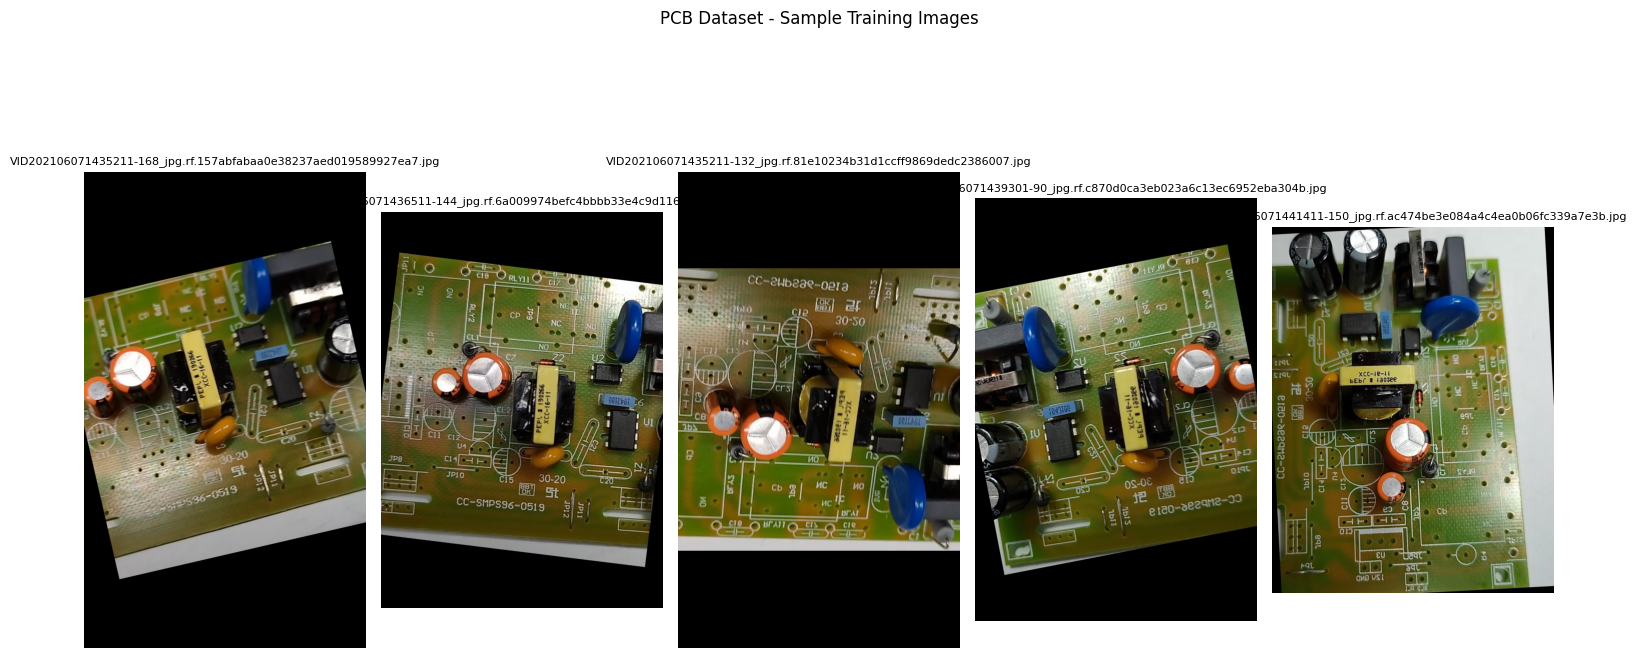

In [7]:
#EDA: Sample PCB images

image_files = [
    f for f in TRAIN_IMAGES.iterdir()
    if f.suffix.lower() in IMAGE_EXTENSIONS
]

sample_images = random.sample(image_files, 5)

plt.figure(figsize=(15, 8))

for i, image_path in enumerate(sample_images):
    img = Image.open(image_path)

    plt.subplot(1, 5, i + 1)
    plt.imshow(img)
    plt.title(image_path.name, fontsize=8)
    plt.axis("off")

plt.suptitle("PCB Dataset - Sample Training Images")
plt.tight_layout()
plt.show()

In [12]:
# EDA: Image Dimensions Analysis

image_data = []

for image_path in TRAIN_IMAGES.iterdir():

    if image_path.suffix.lower() in IMAGE_EXTENSIONS:

        try:
            with Image.open(image_path) as img:

                width, height = img.size

                image_data.append({
                    "Image_Name": image_path.name,
                    "Width": width,
                    "Height": height,
                    "Resolution": width * height
                })

        except Exception as e:
            print("Error:", image_path.name, e)

# Convert into DataFrame
dimensions_df = pd.DataFrame(image_data)

# Display first 5 records
display(dimensions_df.head())

# Statistical Summary
display(dimensions_df[["Width", "Height", "Resolution"]].describe())


,Image_Name,Width,Height,Resolution
0,VID20210601143927-96_jpg.rf.36de73b8200ee94d0b...,1006,1790,1800740
1,VID20210601143927-96_jpg.rf.aa22533cba06977878...,1074,1910,2051340
2,VID20210601143927-96_jpg.rf.be5e4aeaa0b8114ebc...,1052,1870,1967240
3,VID20210601144014-45_jpg.rf.1fc301cb2464b72cbf...,982,1748,1716536
4,VID20210601144014-45_jpg.rf.2348d3566c3d3a8eac...,1018,1810,1842580


,Width,Height,Resolution
count,1099.000000,1099.000000,1.099000e+03
mean,951.250227,1254.638763,1.184885e+06
std,239.214832,147.532256,2.655365e+05
min,772.000000,964.000000,8.458400e+05
25%,840.000000,1156.000000,1.015806e+06
50%,878.000000,1220.000000,1.100440e+06
75%,966.000000,1348.000000,1.247870e+06
max,1920.000000,1910.000000,2.073600e+06


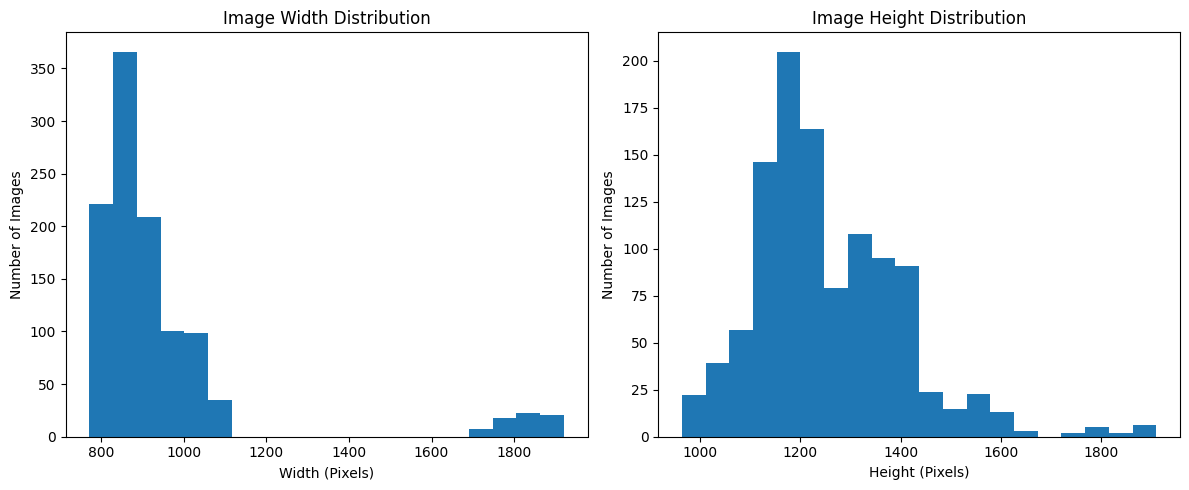

In [13]:
# Image Dimensions Distribution

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(dimensions_df["Width"], bins=20)
plt.title("Image Width Distribution")
plt.xlabel("Width (Pixels)")
plt.ylabel("Number of Images")

plt.subplot(1, 2, 2)
plt.hist(dimensions_df["Height"], bins=20)
plt.title("Image Height Distribution")
plt.xlabel("Height (Pixels)")
plt.ylabel("Number of Images")

plt.tight_layout()
plt.show()

In [14]:
# EDA: Corrupted Image Detection

from PIL import Image

dataset_splits = {
    "Train": TRAIN_IMAGES,
    "Validation": VALID_IMAGES,
    "Test": TEST_IMAGES
}

corrupted_images = []
valid_images = []

for split_name, folder_path in dataset_splits.items():

    print(f"\nChecking {split_name} Images...")

    for image_path in folder_path.iterdir():

        if image_path.suffix.lower() in IMAGE_EXTENSIONS:

            try:
                with Image.open(image_path) as img:
                    img.verify()

                valid_images.append({
                    "Dataset": split_name,
                    "Image": image_path.name
                })

            except Exception as e:
                corrupted_images.append({
                    "Dataset": split_name,
                    "Image": image_path.name,
                    "Error": str(e)
                })

    print(f"{split_name} Check Completed")

print("\nTotal Valid Images:", len(valid_images))
print("Total Corrupted Images:", len(corrupted_images))

print("\nCorrupted Image Details:")

if corrupted_images:
    display(pd.DataFrame(corrupted_images))
else:
    print("No Corrupted Images Found!")


Checking Train Images...
Train Check Completed

Checking Validation Images...
Validation Check Completed

Checking Test Images...
Test Check Completed

Total Valid Images: 1410
Total Corrupted Images: 0

Corrupted Image Details:
No Corrupted Images Found!


In [15]:
# EDA: YOLO Annotation Analysis

from pathlib import Path

label_files = list(TRAIN_LABELS.glob("*.txt"))

print("Total Training Label Files:", len(label_files))

print("\nSample YOLO Annotation Files:\n")

for label_file in label_files[:5]:

    print("File Name:", label_file.name)

    with open(label_file, "r") as file:
        content = file.read().strip()

    if content:
        print("Annotation:")
        print(content)
    else:
        print("Empty Label File")

    print("-" * 50)
    

Total Training Label Files: 1099

Sample YOLO Annotation Files:

File Name: VID20210601143927-96_jpg.rf.36de73b8200ee94d0bd4679407c9cd40.txt
Annotation:
7 0.864314115308151 0.4893854748603352 0.08250497017892644 0.03798882681564246
4 0.5601391650099403 0.43491620111731844 0.14512922465208747 0.07430167597765364
8 0.7495029821073559 0.42877094972067037 0.21769383697813122 0.12290502793296089
2 0.6809145129224652 0.3712290502793296 0.17296222664015903 0.09944134078212291
3 0.5839960238568589 0.34022346368715084 0.16699801192842942 0.10167597765363129
1 0.3797216699801193 0.6427374301675978 0.09642147117296222 0.05418994413407821
0 0.46272365805168986 0.6081005586592179 0.13618290258449303 0.07206703910614524
8 0.48906560636182905 0.529608938547486 0.2504970178926441 0.11843575418994413
5 0.7340954274353877 0.5145251396648045 0.17395626242544732 0.07262569832402235
--------------------------------------------------
File Name: VID20210601143927-96_jpg.rf.aa22533cba06977878022a9bb246d71c.tx

In [16]:
# EDA: Defect Class Distribution

from collections import Counter

class_counts = Counter()

for label_file in TRAIN_LABELS.glob("*.txt"):

    with open(label_file, "r") as file:

        for line in file:

            values = line.strip().split()

            if len(values) == 5:

                class_id = int(float(values[0]))
                class_counts[class_id] += 1

print("Defect Class Distribution:\n")

for class_id, count in sorted(class_counts.items()):
    print(f"Class {class_id}: {count} annotations")

print("\nTotal Defect Annotations:", sum(class_counts.values()))
print("Total Classes:", len(class_counts))

Defect Class Distribution:

Class 0: 1098 annotations
Class 1: 1067 annotations
Class 2: 1003 annotations
Class 3: 872 annotations
Class 4: 1098 annotations
Class 5: 1094 annotations
Class 7: 960 annotations
Class 8: 2162 annotations

Total Defect Annotations: 9354
Total Classes: 8


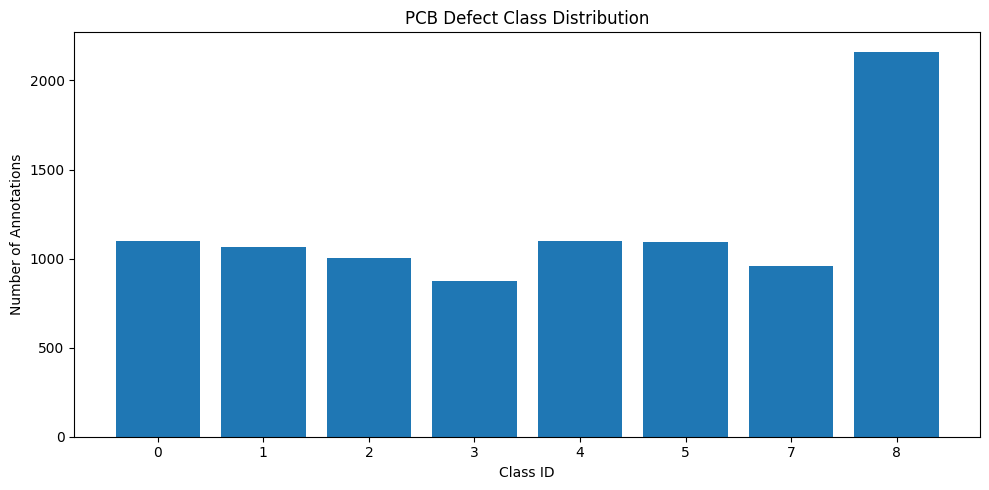

In [17]:
# Defect Class Distribution Chart

plt.figure(figsize=(10, 5))

plt.bar(
    [str(class_id) for class_id in sorted(class_counts.keys())],
    [class_counts[class_id] for class_id in sorted(class_counts.keys())]
)

plt.title("PCB Defect Class Distribution")
plt.xlabel("Class ID")
plt.ylabel("Number of Annotations")

plt.tight_layout()
plt.show()